# 01 · Dados: análise exploratória

**Objetivo:** conhecer a taxa semanal de internações por dengue nos 79 municípios do Rio de Janeiro antes de modelar. Cada gráfico responde a uma pergunta escrita acima dele e termina com uma conclusão.

**Recorte:** a análise usa só **1999 a 2015** (treino + validação). O período de teste (2016 a 2021) fica guardado e só é olhado uma vez, na avaliação final, para que nada do que vemos aqui influencie escolhas com informação do teste.

A carga e a limpeza estão em `src/dengue/dados.py`; este notebook só conta a história.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from dengue import dados

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

FIM_EDA = "2015-12-31"  # fim da validação: o teste fica de fora
tabela = dados.carregar_tabela()
df = tabela[tabela["data"] <= FIM_EDA].reset_index(drop=True)
taxa = dados.pivotar(df, dados.ALVO)          # semanas × municípios
media_estadual = taxa.mean(axis=1)            # média dos 79 municípios por semana

print(f"Tabela completa: {tabela.shape}  |  recorte da EDA: {df.shape}")
print(f"{df['municipio'].nunique()} municípios × {df['data'].nunique()} semanas "
      f"({df['data'].min():%Y-%m-%d} a {df['data'].max():%Y-%m-%d})")
print(f"NAs: {df.isna().sum().sum()}")

Tabela completa: (94721, 14)  |  recorte da EDA: (70073, 14)
79 municípios × 887 semanas (1999-01-01 a 2015-12-25)
NAs: 0


In [2]:
df[[dados.ALVO] + dados.CLIMA + dados.SOCIOECONOMICAS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
taxa,70073.0,0.64,3.29,0.00,0.00,0.00,0.00,215.03
temp_max,70073.0,33.25,2.77,23.28,31.39,33.34,35.24,41.56
precipitacao,70073.0,120.00,108.09,0.00,40.90,89.93,173.60,1926.78
umidade_min,70073.0,64.97,6.47,41.56,60.84,65.57,69.71,81.90
densidade,70073.0,566.10,1769.95,0.00,45.02,87.59,219.52,13372.51
ch4,70073.0,742.34,1329.34,0.00,167.71,230.20,533.11,7576.73
co2,70073.0,137626.11,280393.99,0.00,14478.81,32063.21,112565.18,1896815.65
no2,70073.0,11.68,7.05,0.00,7.61,9.88,13.44,50.22
pobreza,70073.0,18.59,32.14,0.00,6.80,10.33,16.26,394.14
urbanizacao,70073.0,19.87,60.62,0.17,1.63,4.73,16.73,556.33


## 1. Como o alvo se distribui?

Se a maior parte dos valores for zero e houver poucos valores enormes, um erro quadrático direto (MSE) seria dominado pelos picos. Comparamos a distribuição bruta com a distribuição depois de `log1p(y) = log(1 + y)`.

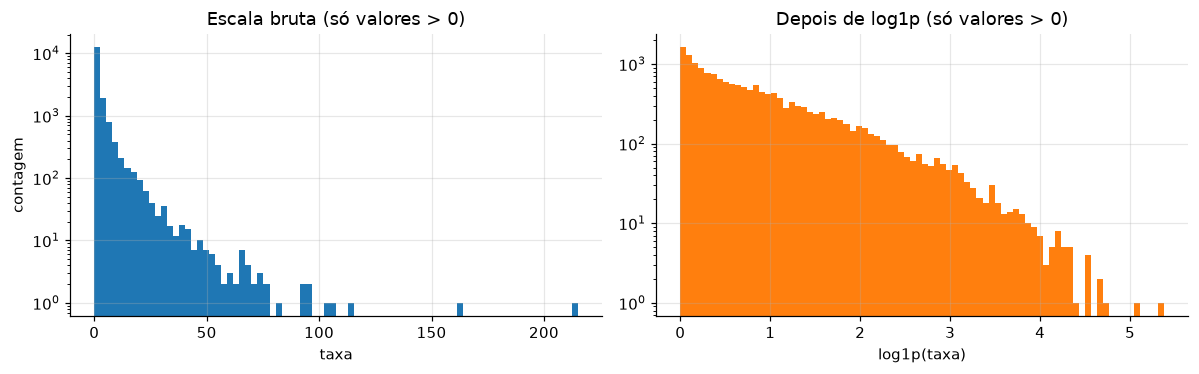

Zeros: 76.3%  |  mediana: 0.00  |  p99: 12.9  |  máximo: 215.0
Assimetria: bruta 16.5  ->  log1p 3.4


In [3]:
positivos = df.loc[df[dados.ALVO] > 0, dados.ALVO]
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5))
eixos[0].hist(positivos, bins=80, color="tab:blue")
eixos[0].set(title="Escala bruta (só valores > 0)", xlabel="taxa", ylabel="contagem", yscale="log")
eixos[1].hist(np.log1p(positivos), bins=80, color="tab:orange")
eixos[1].set(title="Depois de log1p (só valores > 0)", xlabel="log1p(taxa)", yscale="log")
plt.tight_layout(); plt.show()

zeros = (df[dados.ALVO] == 0).mean()
print(f"Zeros: {zeros:.1%}  |  mediana: {df[dados.ALVO].median():.2f}  |  "
      f"p99: {df[dados.ALVO].quantile(0.99):.1f}  |  máximo: {df[dados.ALVO].max():.1f}")
print(f"Assimetria: bruta {df[dados.ALVO].skew():.1f}  ->  log1p {np.log1p(df[dados.ALVO]).skew():.1f}")

**Conclusão:** cerca de 76% das observações são zero, a mediana é 0 e o máximo passa de 200, enquanto 99% dos valores ficam abaixo de 13. A assimetria cai de cerca de 16 para cerca de 3,4 com `log1p`. Por isso o alvo dos modelos será `log1p(taxa)` (task 11), e as métricas voltam para a escala bruta com `expm1`. Como `log1p(0) = 0`, os zeros continuam zero.

## 2. Quando acontecem os surtos?

A série da média estadual mostra se a dengue é um fenômeno contínuo ou concentrado em alguns anos. A faixa cinza marca a validação (2013 a 2015).

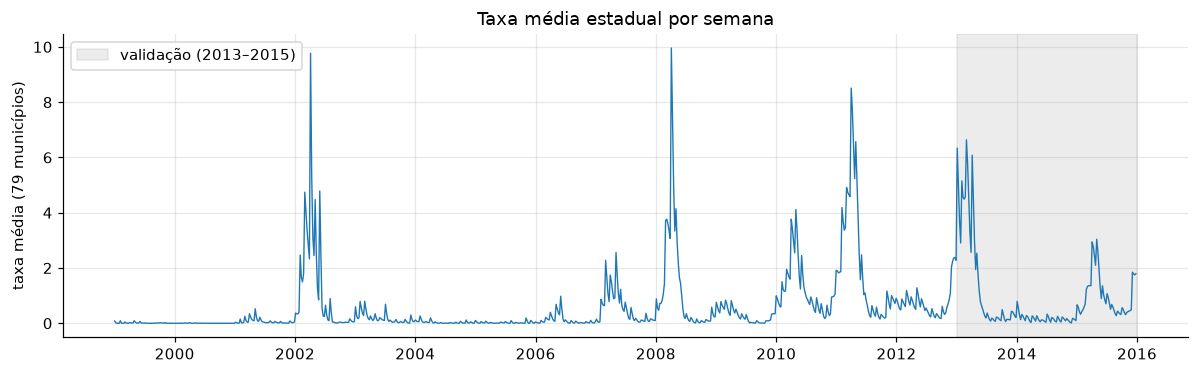

data,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
mean,0.01,0.00,0.07,1.30,0.19,0.04,0.03,0.13,0.57,1.30,0.29,1.26,2.10,0.76,1.71,0.17,1.02
max,0.09,0.02,0.52,9.77,0.80,0.27,0.19,0.98,2.56,9.96,0.84,4.12,8.51,2.38,6.64,0.79,3.04


In [4]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(media_estadual.index, media_estadual.values, lw=0.9, color="tab:blue")
ax.axvspan(np.datetime64("2013-01-01"), np.datetime64(FIM_EDA), color="gray", alpha=0.15,
           label="validação (2013–2015)")
ax.set(title="Taxa média estadual por semana", ylabel="taxa média (79 municípios)")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

por_ano = media_estadual.groupby(media_estadual.index.year).agg(["mean", "max"]).round(2)
por_ano.T

**Conclusão:** a dengue no RJ vem em **surtos**: 2002, 2008, 2010–2011, 2013 e 2015 têm médias anuais acima de 1, enquanto anos como 2000, 2004 e 2005 ficam perto de zero. A validação contém dois surtos (2013 e 2015) e um ano calmo (2014), o que a torna um bom teste de capacidade do modelo. Um modelo útil precisa acertar a subida dos surtos, não só os períodos calmos.

## 3. Em que época do ano a dengue aparece?

Calculamos a média estadual para cada semana do ano (1 a 53), juntando todos os anos. A faixa mostra o intervalo entre os quartis 25% e 75% entre os anos, para ver se o padrão se repete.

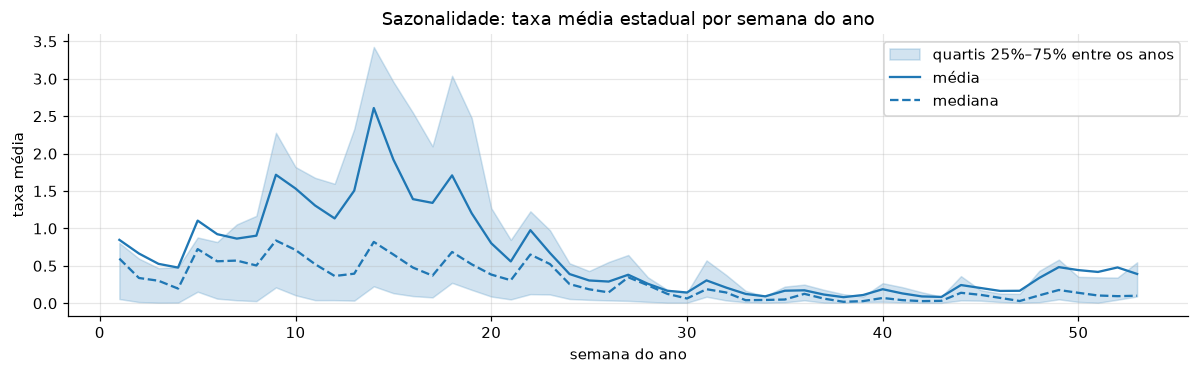

Semana com maior média: 14


In [5]:
semana_do_ano = media_estadual.index.isocalendar().week.to_numpy()
grupos = media_estadual.groupby(semana_do_ano)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.fill_between(grupos.mean().index, grupos.quantile(0.25), grupos.quantile(0.75),
                color="tab:blue", alpha=0.2, label="quartis 25%–75% entre os anos")
ax.plot(grupos.mean().index, grupos.mean().values, color="tab:blue", label="média")
ax.plot(grupos.median().index, grupos.median().values, color="tab:blue", ls="--", label="mediana")
ax.set(title="Sazonalidade: taxa média estadual por semana do ano", xlabel="semana do ano",
       ylabel="taxa média")
ax.legend(); plt.tight_layout(); plt.show()
print(f"Semana com maior média: {grupos.mean().idxmax()}")

**Conclusão:** há uma sazonalidade anual clara. A taxa já sobe em janeiro, tem pico por volta da **semana 14 (início de abril)**, cai a partir de maio e fica baixa de junho a dezembro. Isso justifica a **climatologia** (média histórica de cada semana do ano) como baseline (task 13). A distância entre média e mediana mostra que o pico médio é puxado por poucos anos de surto: a sazonalidade diz *quando* a dengue costuma vir, não *quanto*.

## 4. Os municípios se comportam de forma parecida?

O mapa de calor mostra a taxa média anual de cada município (linhas ordenadas pela média geral). A escala de cor é logarítmica (`log1p`) para que os municípios com taxas baixas também apareçam.

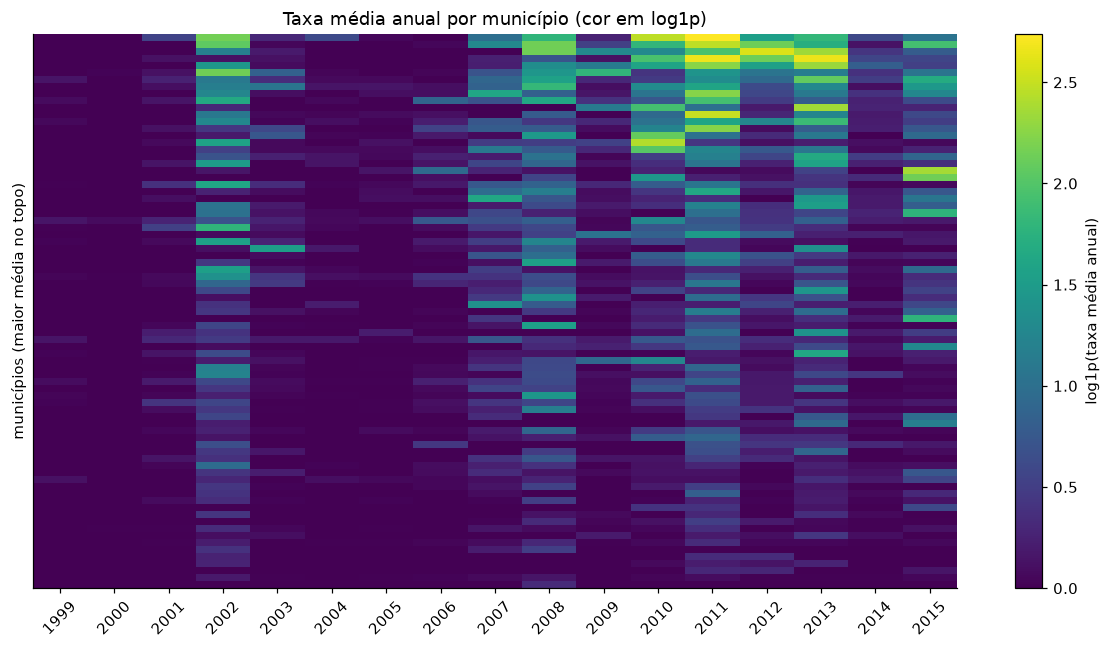

Taxa média por município: mín 0.02, mediana 0.42, máx 3.13
Municípios com mais de 90% de semanas zeradas: 21 de 79


In [6]:
anual = taxa.groupby(taxa.index.year).mean().T          # municípios × anos
anual = anual.loc[anual.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(np.log1p(anual.values), aspect="auto", cmap="viridis")
ax.grid(False)
ax.set_xticks(range(len(anual.columns)), anual.columns, rotation=45)
ax.set_yticks([]); ax.set(ylabel="municípios (maior média no topo)",
                           title="Taxa média anual por município (cor em log1p)")
fig.colorbar(im, ax=ax, label="log1p(taxa média anual)")
plt.tight_layout(); plt.show()

media_mun = taxa.mean()
zeros_mun = (taxa == 0).mean()
print(f"Taxa média por município: mín {media_mun.min():.2f}, mediana {media_mun.median():.2f}, "
      f"máx {media_mun.max():.2f}")
print(f"Municípios com mais de 90% de semanas zeradas: {(zeros_mun > 0.9).sum()} de {len(zeros_mun)}")

**Conclusão:** os anos de surto aparecem como colunas claras que atravessam a maioria dos municípios, ou seja, os surtos são **estaduais**, e não locais. Ao mesmo tempo, a intensidade varia muito: a taxa média vai de 0,02 a 3,1 e 21 municípios têm mais de 90% das semanas zeradas. Os modelos terão de lidar com nós "silenciosos" e nós muito ativos ao mesmo tempo.

## 5. Existe padrão espacial?

Se municípios próximos tiverem taxas parecidas, faz sentido usar um grafo geográfico (task 15). Cada ponto é um município, na sua latitude e longitude, colorido pela taxa média de 1999 a 2015.

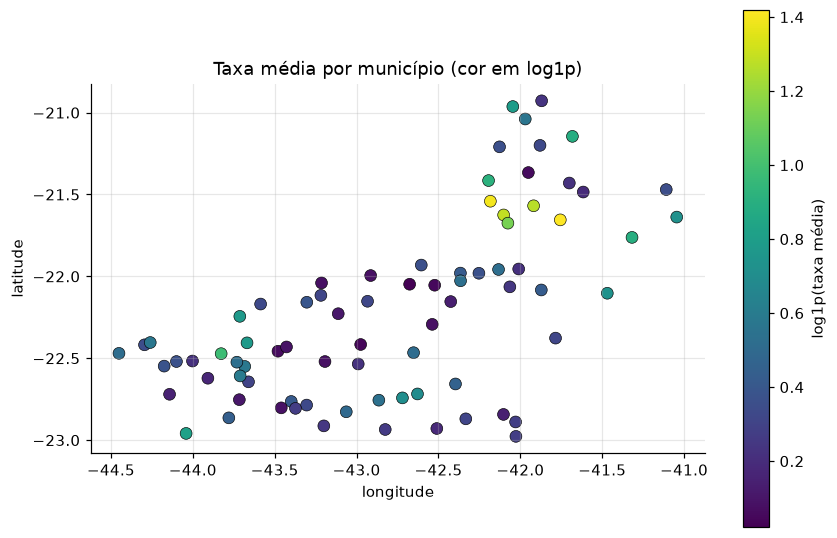

In [7]:
coords = df.groupby("municipio")[["latitude", "longitude"]].first().loc[media_mun.index]
fig, ax = plt.subplots(figsize=(8, 5))
pontos = ax.scatter(coords["longitude"], coords["latitude"], c=np.log1p(media_mun.values),
                    s=60, cmap="viridis", edgecolor="k", lw=0.4)
ax.set(title="Taxa média por município (cor em log1p)", xlabel="longitude", ylabel="latitude")
ax.set_aspect("equal"); fig.colorbar(pontos, ax=ax, label="log1p(taxa média)")
plt.tight_layout(); plt.show()

**Conclusão:** existe um aglomerado claro: os municípios do norte e noroeste do estado (latitude acima de −21,7) concentram as maiores taxas médias. No resto do estado o padrão é mais misturado, com municípios de taxa alta ao lado de municípios de taxa baixa. A dependência espacial parece **regional e moderada**. A task 15 mede isso de forma objetiva (correlação entre vizinhos contra pares aleatórios), e a task 17 testa se o grafo de fato ajuda o STGCN.

## 6. O clima ajuda a prever, e com que atraso?

O mosquito precisa de tempo para se reproduzir depois da chuva e do calor, então o efeito do clima deve aparecer com atraso. Para cada variável climática, calculamos a correlação entre o clima na semana *t − lag* e a taxa na semana *t*, dentro de cada município, e tiramos a média (`dados.correlacao_defasada`). As três variáveis estão no mesmo gráfico para comparação.

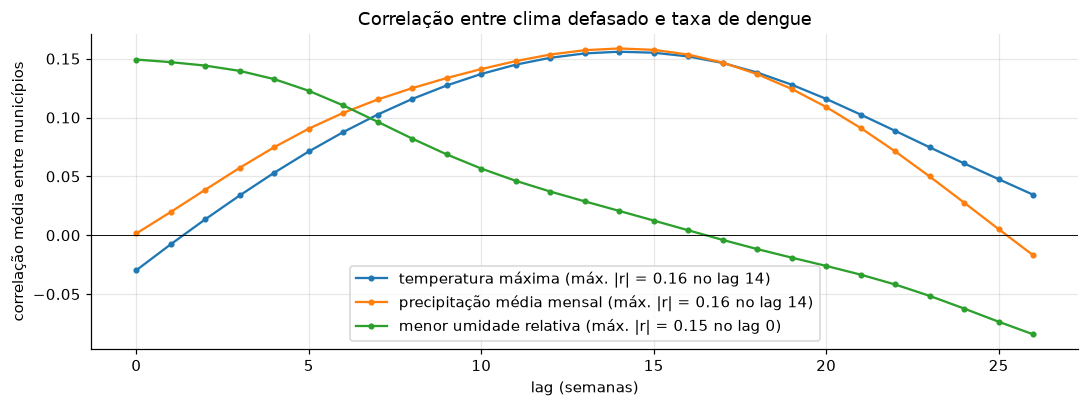

In [8]:
rotulos = {"temp_max": "temperatura máxima", "precipitacao": "precipitação média mensal",
           "umidade_min": "menor umidade relativa"}
fig, ax = plt.subplots(figsize=(10, 3.8))
for coluna in dados.CLIMA:
    r = dados.correlacao_defasada(df, coluna)
    melhor = r.abs().idxmax()
    ax.plot(r.index, r.values, marker="o", ms=3,
            label=f"{rotulos[coluna]} (máx. |r| = {r[melhor]:.2f} no lag {melhor})")
ax.axhline(0, color="k", lw=0.6)
ax.set(title="Correlação entre clima defasado e taxa de dengue", xlabel="lag (semanas)",
       ylabel="correlação média entre municípios")
ax.legend(); plt.tight_layout(); plt.show()

**Conclusão:** no mesmo instante (lag 0), temperatura e chuva quase não se correlacionam com a taxa (|r| ≈ 0). Com atraso de cerca de **14 semanas** (pouco mais de 3 meses), as duas chegam a r ≈ 0,16. A umidade tem r ≈ 0,15 já no lag 0 e vai caindo. As correlações são fracas: o clima ajuda, mas a melhor pista para a taxa futura é a própria taxa recente. Com janela de entrada W = 4 semanas, o modelo não enxerga o atraso de 14 semanas do clima, uma limitação conhecida e aceita para manter o projeto simples.

## 7. As variáveis socioeconômicas são mesmo estáticas?

Densidade, pobreza e urbanização deveriam ser quase constantes por município. Se variarem no tempo, foram interpoladas e podem carregar tendência artificial. Mostramos a densidade de 5 municípios ao longo do tempo, normalizada pelo valor inicial (1 = igual a 1999).

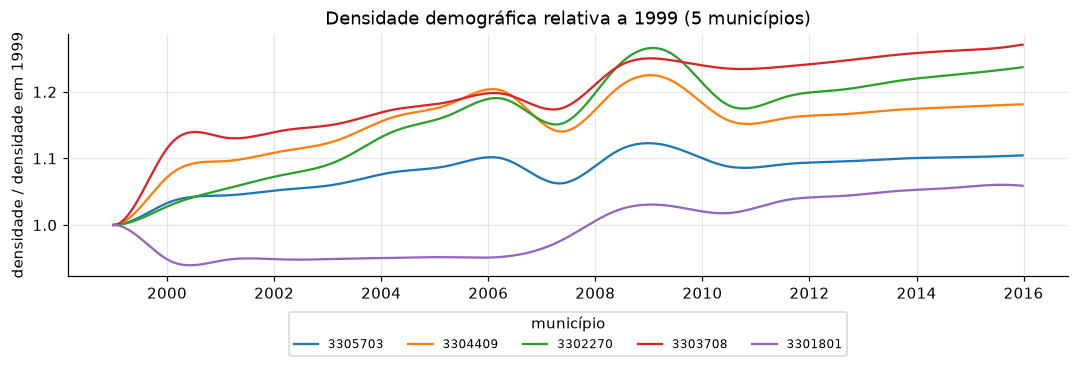

densidade    varia no tempo em 100% dos municípios | correlação com a taxa: -0.023
ch4          varia no tempo em 100% dos municípios | correlação com a taxa: -0.031
co2          varia no tempo em 100% dos municípios | correlação com a taxa: -0.024
no2          varia no tempo em 100% dos municípios | correlação com a taxa: +0.019
pobreza      varia no tempo em 100% dos municípios | correlação com a taxa: +0.036
urbanizacao  varia no tempo em 100% dos municípios | correlação com a taxa: -0.017


In [9]:
densidade = dados.pivotar(df, "densidade")
exemplos = media_mun.sort_values().index[:: len(media_mun) // 5][:5]
fig, ax = plt.subplots(figsize=(10, 3.5))
for mun in exemplos:
    serie = densidade[mun] / densidade[mun].iloc[0]
    ax.plot(serie.index, serie.values, label=str(mun))
ax.set(title="Densidade demográfica relativa a 1999 (5 municípios)", ylabel="densidade / densidade em 1999")
ax.legend(title="município", ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

for coluna in dados.SOCIOECONOMICAS:
    varia = (df.groupby("municipio")[coluna].nunique() > 1).mean()
    r = df[[coluna, dados.ALVO]].corr().iloc[0, 1]
    print(f"{coluna:12s} varia no tempo em {varia:.0%} dos municípios | correlação com a taxa: {r:+.3f}")

**Conclusão:** todas as variáveis "estáticas" variam no tempo em 100% dos municípios, com curvas suaves típicas de interpolação entre censos. Além disso, a correlação simultânea delas com a taxa é desprezível (|r| < 0,04). Por isso, na primeira versão dos modelos, as entradas serão **a própria taxa e as três variáveis climáticas**; as socioeconômicas ficam de fora (decisão registrada na task 10).

## Resumo

1. O alvo tem ~76% de zeros e uma cauda longa: usaremos `log1p` no alvo.
2. A dengue vem em surtos estaduais (2002, 2008, 2010–2011, 2013, 2015); a validação tem dois deles.
3. Há sazonalidade anual com pico em abril: a climatologia é um baseline natural.
4. Os municípios diferem muito em intensidade; 21 deles são quase sempre zero.
5. O padrão espacial existe, mas parece moderado: o ganho do grafo precisa ser medido, não presumido.
6. O clima tem efeito fraco e atrasado (~14 semanas).
7. As variáveis socioeconômicas são interpoladas e quase não se correlacionam com a taxa.